In [1]:
import torch
import torch.nn as nn

from torchvision import models
from torchvision import datasets
from torchvision import transforms

from torch.utils.data import DataLoader

import pandas as pd
import numpy as np

In [2]:
# load test dataset
test_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )

])

In [3]:
# load folder test
test_dataset = datasets.ImageFolder(
    r"C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized\test",
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print(
    test_dataset.classes
)

['joy', 'sadness']


In [4]:
# testing MobileNetV2
mobilenet = models.mobilenet_v2(
    weights=None
)

num_features = (
    mobilenet.classifier[1]
    .in_features
)

mobilenet.classifier[1] = nn.Linear(
    num_features,
    2
)

mobilenet.load_state_dict(
    torch.load(
        "mobilenetv2_best.pth",
        map_location="cpu"
    )
)

mobilenet.eval()

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [5]:
# PREDIKSI MobileNetV2

y_true_mobile = []
y_pred_mobile = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = mobilenet(
            images
        )

        _, preds = torch.max(
            outputs,
            1
        )

        y_true_mobile.extend(
            labels.numpy()
        )

        y_pred_mobile.extend(
            preds.numpy()
        )

In [6]:
# Cek jumlah data

print(
    len(y_true_mobile)
)

print(
    len(y_pred_mobile)
)

56
56


In [7]:
# Testing ResNet18

resnet = models.resnet18(
    weights=None
)

num_features = (
    resnet.fc.in_features
)

resnet.fc = nn.Linear(
    num_features,
    2
)

resnet.load_state_dict(
    torch.load(
        "resnet18_best.pth",
        map_location="cpu"
    )
)

resnet.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [8]:
# prediksi Resnet18

y_true_resnet = []
y_pred_resnet = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = resnet(
            images
        )

        _, preds = torch.max(
            outputs,
            1
        )

        y_true_resnet.extend(
            labels.numpy()
        )

        y_pred_resnet.extend(
            preds.numpy()
        )

In [9]:
# verifikasi

print(
    len(y_true_resnet)
)

print(
    len(y_pred_resnet)
)

56
56


In [10]:
# pastikan label sama

print(
    np.array_equal(
        y_true_mobile,
        y_true_resnet
    )
)

True


In [11]:
# hasil
len(y_true_mobile)
len(y_pred_mobile)
len(y_pred_resnet)

56

In [12]:
# ubah prediksi jadi benar dan salalh

mobile_correct = (
    np.array(y_true_mobile)
    ==
    np.array(y_pred_mobile)
).astype(int)

resnet_correct = (
    np.array(y_true_resnet)
    ==
    np.array(y_pred_resnet)
).astype(int)

print(mobile_correct[:10])
print(resnet_correct[:10])

[1 1 1 1 1 1 1 1 1 1]
[1 1 1 1 1 1 1 1 1 1]


In [26]:
!pip install scipy


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
# jalankan paired t-test
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(
    mobile_correct,
    resnet_correct
)

print(
    "t-statistic =",
    t_stat
)

print(
    "p-value =",
    p_value
)

t-statistic = -1.0
p-value = 0.3216899177205284


In [14]:
# hitung rata2 akurasi per sampel
print(
    "MobileNet Mean =",
    mobile_correct.mean()
)

print(
    "ResNet Mean =",
    resnet_correct.mean()
)

MobileNet Mean = 0.9285714285714286
ResNet Mean = 0.9464285714285714


In [32]:
import sys
import torch
import numpy
import sklearn
import matplotlib
import pandas
import cv2
import mediapipe

print("Python :", sys.version)
print("PyTorch :", torch.__version__)
print("NumPy :", numpy.__version__)
print("Scikit-Learn :", sklearn.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Pandas :", pandas.__version__)
print("OpenCV :", cv2.__version__)
print("MediaPipe :", mediapipe.__version__)

Python : 3.10.5 (tags/v3.10.5:f377153, Jun  6 2022, 16:14:13) [MSC v.1929 64 bit (AMD64)]
PyTorch : 2.12.0+cpu
NumPy : 2.1.3
Scikit-Learn : 1.6.1
Matplotlib : 3.10.6
Pandas : 2.2.3
OpenCV : 4.12.0
MediaPipe : 0.10.14


In [34]:
import torchvision

print("TorchVision :", torchvision.__version__)

TorchVision : 0.27.0+cpu


In [35]:
import streamlit as st

print(st.__version__)

1.45.1


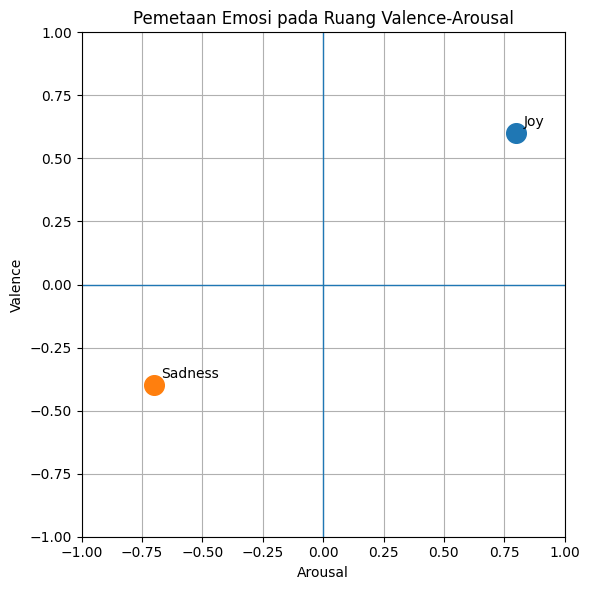

In [2]:
import matplotlib.pyplot as plt

# Data Valence-Arousal

emotions = {
    "Joy": (0.8, 0.6),
    "Sadness": (-0.7, -0.4)
}

fig, ax = plt.subplots(
    figsize=(6, 6)
)

# Garis sumbu

ax.axhline(
    y=0,
    linewidth=1
)

ax.axvline(
    x=0,
    linewidth=1
)

# Plot titik

for emotion, (valence, arousal) in emotions.items():

    ax.scatter(
        valence,
        arousal,
        s=200
    )

    ax.text(
        valence + 0.03,
        arousal + 0.03,
        emotion,
        fontsize=10
    )

# Pengaturan grafik

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)

ax.set_xlabel(
    "Arousal"
)

ax.set_ylabel(
    "Valence"
)

ax.set_title(
    "Pemetaan Emosi pada Ruang Valence-Arousal"
)

ax.grid(True)

plt.tight_layout()

plt.savefig(
    "valence_arousal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()